
# 06 — Predictive Modeling: AQI Forecasting

## Project Objective
Develop a machine learning model to forecast station-level Air Quality Index (AQI) 24 hours ahead using historical air quality observations.

## Business Problem
Air pollution information is more useful when it can help anticipate future conditions. This project aims to use historical AQI patterns, temporal variables, lag features and rolling statistics to forecast future pollution levels.

## Prediction Task
- **Prediction target:** AQI 24 hours ahead
- **Prediction level:** Individual monitoring station
- **Forecast horizon:** 24 hours
- **Problem type:** Supervised regression

## Modeling Workflow
1. Load and validate the feature-engineered dataset.
2. Construct the future AQI target.
3. Perform feature selection and leakage checks.
4. Create chronological train, validation and test datasets.
5. Establish a baseline model.
6. Train and compare machine learning models.
7. Evaluate and interpret model performance.

## Important Methodological Considerations
- Use exact station identity and timestamps.
- Prevent future information from entering model features.
- Use chronological rather than random data splitting.
- Preserve missing values and investigate their impact.
- Evaluate model performance on unseen future observations.

In [3]:

import os
import duckdb
import pandas as pd
import numpy as np

from pathlib import Path

# Project directory
PROJECT_ROOT = Path.cwd().parent

# Dataset path
INPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "air_quality_model_ready.parquet"
)

# DuckDB database
DB_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "air_quality_modeling.duckdb"
)

# Temporary directory
TEMP_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "duckdb_temp"
)

TEMP_PATH.mkdir(parents=True, exist_ok=True)

# Check dataset availability
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {INPUT_PATH}"
    )

# Connect to DuckDB
con = duckdb.connect(str(DB_PATH))

# Configure DuckDB
con.execute("SET memory_limit = '6GB'")
con.execute(f"SET temp_directory = '{TEMP_PATH}'")
con.execute("SET threads = 4")

# Create source view
con.execute(f"""
    CREATE OR REPLACE VIEW air_quality_model_ready AS
    SELECT *
    FROM read_parquet('{INPUT_PATH.as_posix()}')
""")

print("DuckDB connected successfully!")
print("Dataset:", INPUT_PATH)
print("Dataset exists:", INPUT_PATH.exists())


DuckDB connected successfully!
Dataset: c:\Users\khush\Projects\india-air-quality-intelligence\data\processed\air_quality_model_ready.parquet
Dataset exists: True


In [4]:

# Check dataset dimensions
dataset_summary = con.execute("""
    SELECT
        COUNT(*) AS Total_Records,
        COUNT(DISTINCT
            State || '|' ||
            City || '|' ||
            "Station Name"
        ) AS Unique_Stations,
        COUNT(AQI_Valid) AS Valid_AQI_Records,
        MIN(Timestamp) AS First_Timestamp,
        MAX(Timestamp) AS Last_Timestamp,
        MIN(AQI_Valid) AS Minimum_AQI,
        MAX(AQI_Valid) AS Maximum_AQI
    FROM air_quality_model_ready
""").df()

display(dataset_summary)

# Inspect column names and data types
schema = con.execute("""
    DESCRIBE air_quality_model_ready
""").df()

display(schema)


,Total_Records,Unique_Stations,Valid_AQI_Records,First_Timestamp,Last_Timestamp,Minimum_AQI,Maximum_AQI
0,13509072,529,12473485,2017-01-01,2023-12-31 23:00:00,1.0,500.0


,column_name,column_type,null,key,default,extra
0,Station ID,VARCHAR,YES,None,None,None
1,State,VARCHAR,YES,None,None,None
2,City,VARCHAR,YES,None,None,None
3,Station Name,VARCHAR,YES,None,None,None
4,Date,TIMESTAMP,YES,None,None,None
5,Hour,VARCHAR,YES,None,None,None
6,AQI,DOUBLE,YES,None,None,None
7,Timestamp,TIMESTAMP,YES,None,None,None
8,Station,VARCHAR,YES,None,None,None
9,AQI_Status,VARCHAR,YES,None,None,None



## Target Variable Construction

The target variable represents the valid AQI recorded at the same monitoring station exactly 24 hours after the current observation.

An exact timestamp self-join is used to ensure that the forecasting horizon is consistent and that missing timestamps are not mistaken for future observations.


In [5]:

# Create a 24-hour-ahead target using exact timestamp matching

con.execute("""
    CREATE OR REPLACE VIEW aqi_forecasting_target AS

    SELECT
        current.*,
        future.AQI_Valid AS Target_AQI_24H

    FROM air_quality_model_ready AS current

    LEFT JOIN air_quality_model_ready AS future

        ON current.State = future.State
        AND current.City = future.City
        AND current."Station Name" = future."Station Name"

        AND future.Timestamp =
            current.Timestamp + INTERVAL '24 hours'
""")

print("24-hour forecasting target created successfully!")


24-hour forecasting target created successfully!


In [6]:

# Target availability and data validation

target_summary = con.execute("""
    SELECT
        COUNT(*) AS Total_Records,

        COUNT(Target_AQI_24H)
            AS Valid_Future_AQI,

        COUNT(*) - COUNT(Target_AQI_24H)
            AS Missing_Future_AQI,

        ROUND(
            100.0 * COUNT(Target_AQI_24H) / COUNT(*),
            2
        ) AS Target_Availability_Percent,

        MIN(Target_AQI_24H)
            AS Minimum_Target_AQI,

        MAX(Target_AQI_24H)
            AS Maximum_Target_AQI

    FROM aqi_forecasting_target
""").df()

display(target_summary)


,Total_Records,Valid_Future_AQI,Missing_Future_AQI,Target_Availability_Percent,Minimum_Target_AQI,Maximum_Target_AQI
0,13509072,12386080,1122992,91.69,1.0,500.0


In [7]:

sample_targets = con.execute("""
    SELECT
        State,
        City,
        "Station Name",
        Timestamp AS Current_Timestamp,
        Timestamp + INTERVAL '24 hours'
            AS Expected_Target_Timestamp,
        AQI_Valid AS Current_AQI,
        Target_AQI_24H

    FROM aqi_forecasting_target

    WHERE AQI_Valid IS NOT NULL
      AND Target_AQI_24H IS NOT NULL

    ORDER BY RANDOM()

    LIMIT 10
""").df()

display(sample_targets)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,State,City,Station Name,Current_Timestamp,Expected_Target_Timestamp,Current_AQI,Target_AQI_24H
0,Delhi,Delhi,Mundka Delhi DPCC,2019-03-07 18:00:00,2019-03-08 18:00:00,73.0,308.0
1,Bihar,Muzaffarpur,MIT-Daudpur Kothi Muzaffarpur BSPCB,2022-09-04 20:00:00,2022-09-05 20:00:00,131.0,113.0
2,Delhi,Delhi,Shadipur Delhi CPCB,2018-06-25 10:00:00,2018-06-26 10:00:00,204.0,80.0
3,Kerala,Kochi,Vyttila Kochi Kerala PCB,2022-01-31 07:00:00,2022-02-01 07:00:00,236.0,65.0
4,Uttar Pradesh,Lucknow,Kendriya Vidyalaya Lucknow CPCB,2023-06-03 23:00:00,2023-06-04 23:00:00,108.0,74.0
5,Bihar,Gaya,SFTI Kusdihra Gaya BSPCB,2020-03-27 01:00:00,2020-03-28 01:00:00,41.0,94.0
6,Maharashtra,Mumbai,Vasai West Mumbai MPCB,2021-06-08 21:00:00,2021-06-09 21:00:00,40.0,38.0
7,Karnataka,Bengaluru,Hombegowda Nagar Bengaluru KSPCB,2020-09-15 15:00:00,2020-09-16 15:00:00,29.0,32.0
8,Bihar,Motihari,Gandak Colony Motihari BSPCB,2022-12-15 18:00:00,2022-12-16 18:00:00,230.0,55.0
9,Delhi,Delhi,Major Dhyan Chand National Stadium Delhi DPCC,2022-01-31 16:00:00,2022-02-01 16:00:00,397.0,350.0



## Target Availability Analysis

Investigate why some observations do not have a valid AQI target exactly 24 hours ahead.

Distinguish between missing future timestamps and future timestamps with missing or invalid AQI measurements.


In [8]:

target_availability = con.execute("""
    SELECT
        COUNT(*) AS Total_Records,

        COUNT(*) FILTER (
            WHERE future.Timestamp IS NULL
        ) AS Future_Timestamp_Not_Found,

        COUNT(*) FILTER (
            WHERE future.Timestamp IS NOT NULL
              AND future.AQI_Valid IS NULL
        ) AS Future_AQI_Missing_Or_Invalid,

        COUNT(*) FILTER (
            WHERE future.AQI_Valid IS NOT NULL
        ) AS Valid_Future_Targets

    FROM air_quality_model_ready AS current

    LEFT JOIN air_quality_model_ready AS future

        ON current.State = future.State
        AND current.City = future.City
        AND current."Station Name" = future."Station Name"

        AND future.Timestamp =
            current.Timestamp + INTERVAL '24 hours'
""").df()

display(target_availability)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Total_Records,Future_Timestamp_Not_Found,Future_AQI_Missing_Or_Invalid,Valid_Future_Targets
0,13509072,214128,908864,12386080


In [9]:

feature_availability = con.execute("""
    SELECT
        COUNT(*) AS Total_Records,

        COUNT(*) FILTER (
            WHERE AQI_Valid IS NOT NULL
        ) AS Current_AQI_Available,

        COUNT(AQI_Lag_1H) AS Lag_1H_Available,
        COUNT(AQI_Lag_24H) AS Lag_24H_Available,
        COUNT(AQI_Lag_168H) AS Lag_168H_Available,

        COUNT(AQI_Rolling_Mean_24H)
            AS Rolling_24H_Available,

        COUNT(AQI_Rolling_Mean_7D)
            AS Rolling_7D_Available

    FROM air_quality_model_ready
""").df()

display(feature_availability)


,Total_Records,Current_AQI_Available,Lag_1H_Available,Lag_24H_Available,Lag_168H_Available,Rolling_24H_Available,Rolling_7D_Available
0,13509072,12473485,12472563,12365127,12019379,12157246,11932485


## Chronological Train, Validation and Test Split

To evaluate the 24-hour AQI forecasting model realistically, the dataset
will be divided chronologically using the target timestamp.

- Training: Target timestamp before 2022-01-01
- Validation: Target timestamp during 2022
- Testing: Target timestamp during 2023

Only records with valid current AQI and valid future AQI targets
will be considered for supervised model training.

This approach avoids random splitting and reduces temporal data leakage.

In [10]:
split_summary = con.execute("""
WITH eligible_data AS (
    SELECT
        Timestamp,
        Timestamp + INTERVAL '24 hours' AS Target_Timestamp,
        AQI_Valid,
        Target_AQI_24H
    FROM aqi_forecasting_target
    WHERE AQI_Valid IS NOT NULL
      AND Target_AQI_24H IS NOT NULL
)

SELECT
    CASE
        WHEN Target_Timestamp < TIMESTAMP '2022-01-01'
            THEN 'Training (2017–2021)'

        WHEN Target_Timestamp >= TIMESTAMP '2022-01-01'
         AND Target_Timestamp < TIMESTAMP '2023-01-01'
            THEN 'Validation (2022)'

        WHEN Target_Timestamp >= TIMESTAMP '2023-01-01'
         AND Target_Timestamp < TIMESTAMP '2024-01-01'
            THEN 'Testing (2023)'
    END AS Dataset_Split,

    COUNT(*) AS Record_Count,
    MIN(Timestamp) AS Earliest_Feature_Timestamp,
    MAX(Timestamp) AS Latest_Feature_Timestamp,
    MIN(Target_Timestamp) AS Earliest_Target_Timestamp,
    MAX(Target_Timestamp) AS Latest_Target_Timestamp

FROM eligible_data

GROUP BY Dataset_Split
ORDER BY Dataset_Split
""").df()

display(split_summary)

,Dataset_Split,Record_Count,Earliest_Feature_Timestamp,Latest_Feature_Timestamp,Earliest_Target_Timestamp,Latest_Target_Timestamp
0,Testing (2023),3294948,2022-12-31,2023-12-30 23:00:00,2023-01-01,2023-12-31 23:00:00
1,Training (2017–2021),5970924,2017-01-01,2021-12-30 23:00:00,2017-01-02,2021-12-31 23:00:00
2,Validation (2022),2398361,2021-12-31,2022-12-30 23:00:00,2022-01-01,2022-12-31 23:00:00


## Baseline Model — Persistence Forecast

Before training machine-learning models, we establish a simple
persistence baseline.

The baseline assumes that the AQI observed at the current hour
will remain unchanged 24 hours later.

This provides a reference point against which the predictive
performance of more advanced models can be evaluated.

Evaluation metrics:
- MAE: Mean Absolute Error
- RMSE: Root Mean Squared Error
- R²: Coefficient of Determination

In [13]:
baseline_results = con.execute("""
WITH eligible_data AS (
    SELECT
        Timestamp,
        Timestamp + INTERVAL '24 hours' AS Target_Timestamp,
        AQI_Valid AS Actual_Current_AQI,
        Target_AQI_24H AS Actual_Future_AQI,

        CASE
            WHEN Timestamp + INTERVAL '24 hours'
                 < TIMESTAMP '2022-01-01'
                THEN 'Training (2017–2021)'

            WHEN Timestamp + INTERVAL '24 hours'
                 < TIMESTAMP '2023-01-01'
                THEN 'Validation (2022)'

            ELSE 'Testing (2023)'
        END AS Dataset_Split

    FROM aqi_forecasting_target

    WHERE AQI_Valid IS NOT NULL
      AND Target_AQI_24H IS NOT NULL
),

predictions AS (
    SELECT
        *,
        Actual_Current_AQI AS Predicted_Future_AQI
    FROM eligible_data
),

split_averages AS (
    SELECT
        Dataset_Split,
        AVG(Actual_Future_AQI) AS Mean_Future_AQI
    FROM predictions
    GROUP BY Dataset_Split
),

metrics AS (
    SELECT
        p.Dataset_Split,
        COUNT(*) AS Record_Count,

        AVG(ABS(
            p.Actual_Future_AQI - p.Predicted_Future_AQI
        )) AS MAE,

        SQRT(AVG(POWER(
            p.Actual_Future_AQI - p.Predicted_Future_AQI, 2
        ))) AS RMSE,

        SUM(POWER(
            p.Actual_Future_AQI - p.Predicted_Future_AQI, 2
        )) AS SSE,

        SUM(POWER(
            p.Actual_Future_AQI - a.Mean_Future_AQI, 2
        )) AS SST

    FROM predictions p

    JOIN split_averages a
        ON p.Dataset_Split = a.Dataset_Split

    GROUP BY p.Dataset_Split
)

SELECT
    Dataset_Split,
    Record_Count,
    ROUND(MAE, 2) AS MAE,
    ROUND(RMSE, 2) AS RMSE,
    ROUND(1 - SSE / NULLIF(SST, 0), 4) AS R2

FROM metrics

ORDER BY
    CASE Dataset_Split
        WHEN 'Training (2017–2021)' THEN 1
        WHEN 'Validation (2022)' THEN 2
        WHEN 'Testing (2023)' THEN 3
    END
""").df()

display(baseline_results)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,Dataset_Split,Record_Count,MAE,RMSE,R2
0,Training (2017–2021),5970924,44.96,73.97,0.5767
1,Validation (2022),2398361,42.26,70.41,0.5464
2,Testing (2023),3294948,39.00,66.94,0.5228


In [14]:
import importlib.util

packages = [
    "sklearn",
    "lightgbm",
    "xgboost",
    "catboost"
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")

sklearn: Installed
lightgbm: Not installed
xgboost: Not installed
catboost: Not installed


## Prepare Modelling Dataset

Due to the size of the hourly dataset, a reproducible sample
will be extracted from each chronological split.

- Training sample: 300,000 observations
- Validation sample: 100,000 observations
- Testing sample: 100,000 observations

The samples preserve the chronological split boundaries.

Missing predictor values will be retained because the selected
HistGradientBoostingRegressor supports missing values natively.

In [15]:
sample_sizes = {
    "Training": 300_000,
    "Validation": 100_000,
    "Testing": 100_000
}

sample_queries = []

for split_name, sample_size in sample_sizes.items():

    if split_name == "Training":
        date_condition = """
            Timestamp + INTERVAL '24 hours'
            < TIMESTAMP '2022-01-01'
        """

    elif split_name == "Validation":
        date_condition = """
            Timestamp + INTERVAL '24 hours'
            >= TIMESTAMP '2022-01-01'
            AND Timestamp + INTERVAL '24 hours'
            < TIMESTAMP '2023-01-01'
        """

    else:
        date_condition = """
            Timestamp + INTERVAL '24 hours'
            >= TIMESTAMP '2023-01-01'
            AND Timestamp + INTERVAL '24 hours'
            < TIMESTAMP '2024-01-01'
        """

    query = f"""
    SELECT *
    FROM (
        SELECT
            Timestamp,
            AQI_Valid,
            Target_AQI_24H,
            AQI_Lag_1H,
            AQI_Lag_24H,
            AQI_Lag_168H,
            AQI_Rolling_Mean_24H,
            AQI_Rolling_Mean_7D,
            AQI_Rolling_Count_24H,
            AQI_Rolling_Count_7D,
            Hour_Number,
            Month,
            DayOfWeek,
            Is_Weekend,
            Hour_Sin,
            Hour_Cos,
            Month_Sin,
            Month_Cos,
            DayOfWeek_Sin,
            DayOfWeek_Cos
        FROM aqi_forecasting_target
        WHERE AQI_Valid IS NOT NULL
          AND Target_AQI_24H IS NOT NULL
          AND {date_condition}
    ) AS eligible
    USING SAMPLE reservoir({sample_size} ROWS)
    REPEATABLE (42)
    """

    sample_queries.append(
        f"SELECT '{split_name}' AS Dataset_Split, * FROM ({query})"
    )

combined_query = "\nUNION ALL\n".join(sample_queries)

model_data = con.execute(combined_query).df()

print("Sample shape:", model_data.shape)
print("\nSplit counts:")
display(model_data["Dataset_Split"].value_counts().to_frame("Records"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Sample shape: (500000, 21)

Split counts:


,Records
Dataset_Split,
Training,300000
Validation,100000
Testing,100000


In [16]:
# 1. Define predictor columns

feature_columns = [
    "AQI_Valid",
    "AQI_Lag_1H",
    "AQI_Lag_24H",
    "AQI_Lag_168H",
    "AQI_Rolling_Mean_24H",
    "AQI_Rolling_Mean_7D",
    "AQI_Rolling_Count_24H",
    "AQI_Rolling_Count_7D",
    "Hour_Number",
    "Month",
    "DayOfWeek",
    "Is_Weekend",
    "Hour_Sin",
    "Hour_Cos",
    "Month_Sin",
    "Month_Cos",
    "DayOfWeek_Sin",
    "DayOfWeek_Cos"
]

target_column = "Target_AQI_24H"


# 2. Separate the datasets

train_data = model_data[
    model_data["Dataset_Split"] == "Training"
].copy()

val_data = model_data[
    model_data["Dataset_Split"] == "Validation"
].copy()

test_data = model_data[
    model_data["Dataset_Split"] == "Testing"
].copy()


# 3. Create feature matrices

X_train = train_data[feature_columns]
X_val = val_data[feature_columns]
X_test = test_data[feature_columns]


# 4. Create target arrays

y_train = train_data[target_column]
y_val = val_data[target_column]
y_test = test_data[target_column]


# 5. Check dataset dimensions

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nTarget dimensions:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

Training features: (300000, 18)
Validation features: (100000, 18)
Testing features: (100000, 18)

Target dimensions:
Training: (300000,)
Validation: (100000,)
Testing: (100000,)


In [17]:
# Missing values in each dataset

missing_summary = pd.DataFrame({
    "Training_Missing": X_train.isnull().sum(),
    "Validation_Missing": X_val.isnull().sum(),
    "Testing_Missing": X_test.isnull().sum()
})

display(missing_summary)

print("\nFeature data types:")
display(X_train.dtypes.to_frame("Data_Type"))

print("\nTarget missing values:")
print("Training:", y_train.isnull().sum())
print("Validation:", y_val.isnull().sum())
print("Testing:", y_test.isnull().sum())

,Training_Missing,Validation_Missing,Testing_Missing
AQI_Valid,0,0,0
AQI_Lag_1H,4710,1984,1272
AQI_Lag_24H,17592,6320,5894
AQI_Lag_168H,28132,9096,9004
AQI_Rolling_Mean_24H,16465,5614,5634
AQI_Rolling_Mean_7D,26179,8101,8839
AQI_Rolling_Count_24H,0,0,0
AQI_Rolling_Count_7D,0,0,0
Hour_Number,0,0,0
Month,0,0,0



Feature data types:


,Data_Type
AQI_Valid,float64
AQI_Lag_1H,float64
AQI_Lag_24H,float64
AQI_Lag_168H,float64
AQI_Rolling_Mean_24H,float64
AQI_Rolling_Mean_7D,float64
AQI_Rolling_Count_24H,int64
AQI_Rolling_Count_7D,int64
Hour_Number,int64
Month,int64



Target missing values:
Training: 0
Validation: 0
Testing: 0


## Model 1 — HistGradientBoosting Regressor

A histogram-based gradient boosting regression model is trained
to forecast AQI 24 hours ahead.

The model uses current AQI, historical AQI observations,
rolling statistics and temporal features.

Missing predictor values are handled natively by the estimator.

The model is trained on the training sample and evaluated
on the separate validation sample.

In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Initialize model
hgb_model = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=200,
    max_leaf_nodes=31,
    min_samples_leaf=30,
    l2_regularization=1.0,
    early_stopping=True,
    random_state=42
)

# Train model
start_time = time.time()

hgb_model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"Model training completed in {training_time:.2f} seconds")
print(f"Iterations used: {hgb_model.n_iter_}")

Model training completed in 2.38 seconds
Iterations used: 200


In [19]:
# Generate validation predictions
val_predictions = hgb_model.predict(X_val)

# Calculate evaluation metrics
hgb_val_metrics = {
    "Model": "HistGradientBoosting",
    "MAE": mean_absolute_error(y_val, val_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val, val_predictions)),
    "R2": r2_score(y_val, val_predictions)
}

# Persistence baseline on the exact same validation sample
baseline_val_metrics = {
    "Model": "Persistence Baseline",
    "MAE": mean_absolute_error(
        y_val,
        X_val["AQI_Valid"]
    ),
    "RMSE": np.sqrt(mean_squared_error(
        y_val,
        X_val["AQI_Valid"]
    )),
    "R2": r2_score(
        y_val,
        X_val["AQI_Valid"]
    )
}

validation_comparison = pd.DataFrame([
    baseline_val_metrics,
    hgb_val_metrics
])

validation_comparison[["MAE", "RMSE", "R2"]] = (
    validation_comparison[["MAE", "RMSE", "R2"]].round(3)
)

display(validation_comparison)

,Model,MAE,RMSE,R2
0,Persistence Baseline,42.015,69.906,0.550
1,HistGradientBoosting,38.848,59.651,0.672


## Model Tuning

The initial HistGradientBoosting model reached its maximum
of 200 iterations.

We will evaluate additional boosting iterations while keeping
the other hyperparameters fixed.

The validation set will be used to select the final configuration.
The test set will remain reserved for final evaluation.

In [20]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Candidate iteration settings
iteration_options = [200, 400, 600]

tuning_results = []
tuned_models = {}

for iterations in iteration_options:

    model = HistGradientBoostingRegressor(
        learning_rate=0.08,
        max_iter=iterations,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=42
    )

    start_time = time.time()

    model.fit(X_train, y_train)

    elapsed_time = time.time() - start_time

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    tuning_results.append({
        "Max_Iterations": iterations,
        "Actual_Iterations": model.n_iter_,
        "Training_Time_Seconds": round(elapsed_time, 2),
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "R2": round(r2, 4)
    })

    tuned_models[iterations] = model

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)

,Max_Iterations,Actual_Iterations,Training_Time_Seconds,MAE,RMSE,R2
0,200,200,5.32,38.848,59.651,0.6722
1,400,366,7.45,38.912,59.788,0.6707
2,600,366,6.60,38.912,59.788,0.6707


## Final Model Evaluation

The best-performing configuration was selected using validation data.

The selected HistGradientBoostingRegressor with 200 iterations
will now be evaluated on the untouched 2023 test sample.

Its performance will be compared against the persistence baseline
using the same test observations.

The test set is used only for final evaluation and not for
hyperparameter selection.

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Select best model from tuning
best_model = tuned_models[200]

# Generate predictions on untouched test data
test_predictions = best_model.predict(X_test)

# Evaluate machine learning model
test_model_metrics = {
    "Model": "HistGradientBoosting",
    "MAE": mean_absolute_error(y_test, test_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
    "R2": r2_score(y_test, test_predictions)
}

# Evaluate persistence baseline on identical test observations
test_baseline_predictions = X_test["AQI_Valid"]

test_baseline_metrics = {
    "Model": "Persistence Baseline",
    "MAE": mean_absolute_error(y_test, test_baseline_predictions),
    "RMSE": np.sqrt(mean_squared_error(
        y_test, test_baseline_predictions
    )),
    "R2": r2_score(y_test, test_baseline_predictions)
}

# Create comparison
final_test_results = pd.DataFrame([
    test_baseline_metrics,
    test_model_metrics
])

final_test_results[["MAE", "RMSE", "R2"]] = (
    final_test_results[["MAE", "RMSE", "R2"]].round(4)
)

display(final_test_results)


# Calculate percentage improvement
baseline_mae = test_baseline_metrics["MAE"]
model_mae = test_model_metrics["MAE"]

baseline_rmse = test_baseline_metrics["RMSE"]
model_rmse = test_model_metrics["RMSE"]

mae_improvement = (
    (baseline_mae - model_mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - model_rmse) / baseline_rmse
) * 100

print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")
print(
    f"R2 improvement: "
    f"{test_model_metrics['R2'] - test_baseline_metrics['R2']:.4f}"
)

,Model,MAE,RMSE,R2
0,Persistence Baseline,38.8608,66.6367,0.5271
1,HistGradientBoosting,35.9109,56.5705,0.6592


MAE improvement: 7.59%
RMSE improvement: 15.11%
R2 improvement: 0.1321


## Actual vs Predicted AQI

This section evaluates how closely the model's predicted AQI values
match the actual AQI observations in the 2023 test sample.

Visual analysis helps identify prediction bias, deviations and
potential weaknesses in forecasting performance.

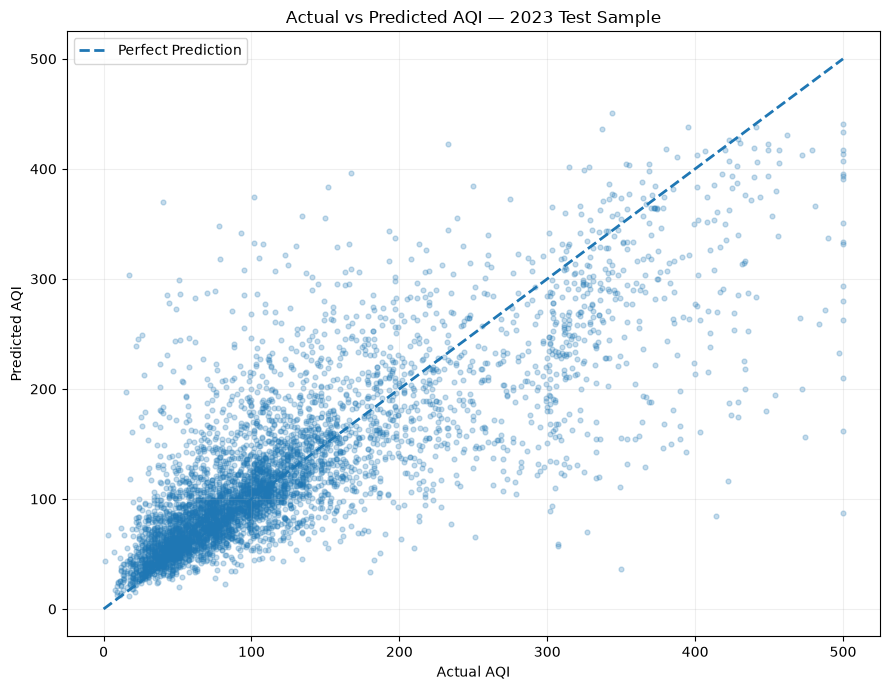

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Reproducible subset for visualization
plot_sample = pd.DataFrame({
    "Actual_AQI": y_test.values,
    "Predicted_AQI": test_predictions
}).sample(n=5000, random_state=42)

# Actual vs Predicted scatter plot
plt.figure(figsize=(9, 7))

plt.scatter(
    plot_sample["Actual_AQI"],
    plot_sample["Predicted_AQI"],
    alpha=0.25,
    s=12
)

# Perfect prediction reference line
plt.plot(
    [0, 500],
    [0, 500],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual vs Predicted AQI — 2023 Test Sample")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

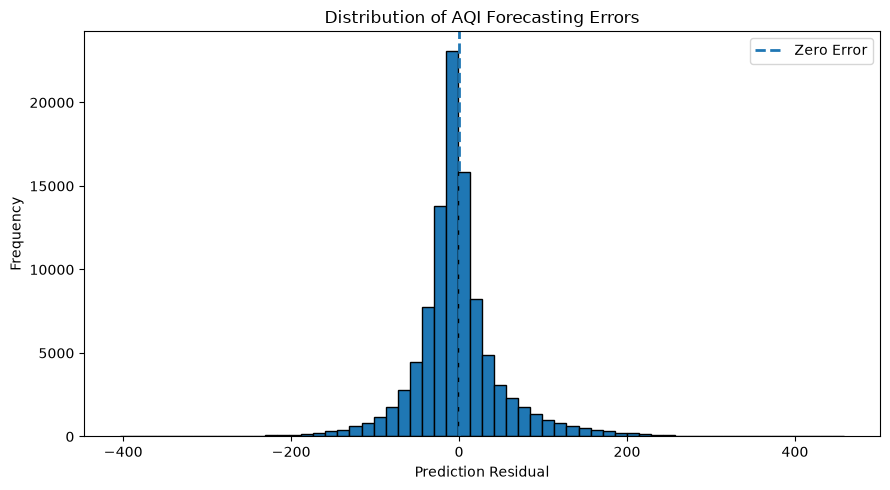

In [23]:
residuals = y_test.values - test_predictions

plt.figure(figsize=(9, 5))

plt.hist(residuals, bins=60, edgecolor="black")

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.xlabel("Prediction Residual")
plt.ylabel("Frequency")
plt.title("Distribution of AQI Forecasting Errors")
plt.legend()
plt.tight_layout()
plt.show()

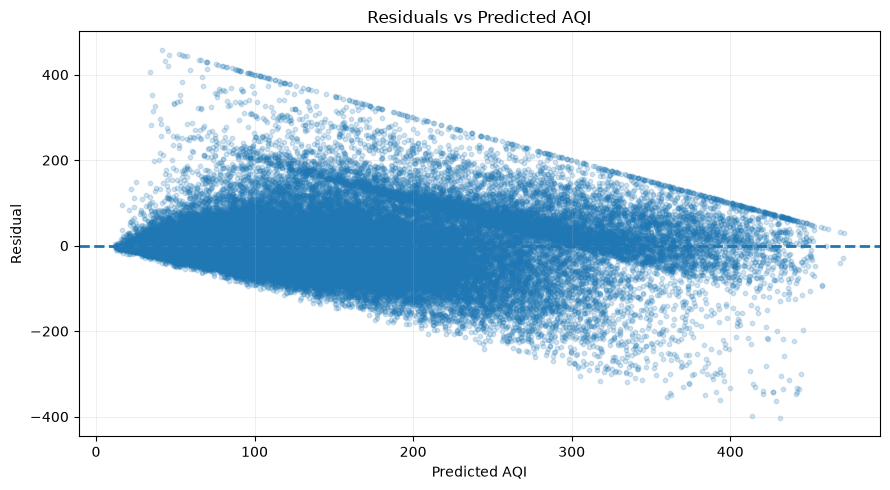

In [24]:
plt.figure(figsize=(9, 5))

plt.scatter(
    test_predictions,
    residuals,
    alpha=0.2,
    s=10
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=2
)

plt.xlabel("Predicted AQI")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted AQI")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


### Model Diagnostic Findings

The diagnostic plots indicate that the HistGradientBoostingRegressor captures the general relationship between current and future AQI values.

Key observations:

1. **Actual vs Predicted:** Predictions generally follow the perfect-prediction line, although dispersion increases at higher AQI levels. Extreme pollution observations are sometimes underpredicted.

2. **Residual Distribution:** Residuals are concentrated around zero, indicating reasonable overall prediction accuracy. However, the distribution has long tails, showing that some observations have substantial forecasting errors.

3. **Residuals vs Predicted:** The residual plot exhibits a widening, funnel-like pattern, suggesting heteroscedasticity. Prediction uncertainty appears to increase at higher predicted AQI values. The triangular boundaries are also influenced by the bounded AQI range of 1–500.

Overall, the model demonstrates useful forecasting performance but is less reliable for extreme pollution conditions. This limitation should be considered when translating predictions into pollution-risk insights.


In [25]:

from sklearn.inspection import permutation_importance
import pandas as pd

# Use a reproducible 10,000-row subset of the test data
importance_sample = X_test.sample(
    n=10_000,
    random_state=42
)

importance_targets = y_test.loc[importance_sample.index]

# Calculate permutation importance
permutation_results = permutation_importance(
    best_model,
    importance_sample,
    importance_targets,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# Create a readable results table
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
}).sort_values(
    by="Importance_Mean",
    ascending=False
)

feature_importance


,Feature,Importance_Mean,Importance_Std
0,AQI_Valid,8.652692,0.192445
5,AQI_Rolling_Mean_7D,6.882637,0.218378
4,AQI_Rolling_Mean_24H,3.076111,0.109060
1,AQI_Lag_1H,2.035072,0.067262
2,AQI_Lag_24H,1.030188,0.048290
3,AQI_Lag_168H,0.799336,0.032373
8,Hour_Number,0.257404,0.030634
15,Month_Cos,0.234154,0.017789
9,Month,0.116144,0.034176
14,Month_Sin,0.108381,0.018128



### Feature Importance Analysis

Permutation feature importance was calculated on a reproducible sample of 10,000 observations from the 2023 test dataset, using negative mean absolute error as the scoring metric and three permutation repeats.

Key findings:

1. Current AQI (`AQI_Valid`) was the most influential predictor, with an importance score of approximately 8.65 AQI points.
2. The 7-day rolling average was the second most influential feature (6.88), followed by the 24-hour rolling average (3.08).
3. Short-term historical measurements, particularly the 1-hour lag (2.04), contributed additional predictive information.
4. Calendar-based features had comparatively low importance. Hour and month features contributed some information, while weekday and weekend indicators had limited influence.
5. Rolling observation counts had approximately zero importance in this evaluation.

**Business interpretation:**

The results suggest that AQI forecasting is driven primarily by recent pollution conditions and historical pollution trends. This supports the importance of maintaining reliable, recent monitoring data when building short-term air-quality forecasting systems.

**Limitation:** Permutation importance measures predictive dependence, not causality. Correlated predictors can share or mask importance, and the results are specific to the evaluated test sample.


In [26]:

import joblib
import json
from datetime import datetime, timezone

# Create model output directory
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "aqi_24h_hist_gradient_boosting.joblib"

# Save trained model
joblib.dump(best_model, MODEL_PATH)

print("Model saved successfully!")
print("Location:", MODEL_PATH)
print("File size (MB):", round(MODEL_PATH.stat().st_size / (1024 ** 2), 2))


Model saved successfully!
Location: c:\Users\khush\Projects\india-air-quality-intelligence\models\aqi_24h_hist_gradient_boosting.joblib
File size (MB): 0.71


In [27]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate final test metrics
test_baseline_predictions = X_test["AQI_Valid"].values

test_metrics = {
    "baseline": {
        "MAE": float(mean_absolute_error(y_test, test_baseline_predictions)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, test_baseline_predictions))),
        "R2": float(r2_score(y_test, test_baseline_predictions))
    },
    "model": {
        "MAE": float(mean_absolute_error(y_test, test_predictions)),
        "RMSE": float(np.sqrt(mean_squared_error(y_test, test_predictions))),
        "R2": float(r2_score(y_test, test_predictions))
    }
}

test_metrics


{'baseline': {'MAE': 38.86084,
  'RMSE': 66.63667443682945,
  'R2': 0.5270664309825353},
 'model': {'MAE': 35.91094435265874,
  'RMSE': 56.570461682218536,
  'R2': 0.6591581157077917}}

In [28]:

metadata = {
    "project": "India Air Quality Intelligence",
    "model_name": "HistGradientBoostingRegressor",
    "prediction_task": "24-hour AQI forecasting",
    "target": "Target_AQI_24H",
    "features": list(X_train.columns),
    "training_period": "2017-2021",
    "validation_period": "2022",
    "testing_period": "2023",
    "sample_sizes": {
        "training": len(X_train),
        "validation": len(X_val),
        "testing": len(X_test)
    },
    "model_parameters": best_model.get_params(),
    "test_metrics": test_metrics,
    "evaluation_method": "Chronological split; deterministic sample of 100,000 test observations",
    "limitations": [
        "Evaluated on a sample of the 2023 test population, not the full population.",
        "Evaluates future observations for known monitoring stations, not unseen stations.",
        "Prediction errors increase at higher AQI levels.",
        "AQI values are bounded between 1 and 500.",
        "Permutation importance is not a measure of causality."
    ],
    "created_at_utc": datetime.now(timezone.utc).isoformat()
}

METADATA_PATH = MODEL_DIR / "aqi_24h_model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4, default=str)

print("Metadata saved successfully!")
print("Location:", METADATA_PATH)


Metadata saved successfully!
Location: c:\Users\khush\Projects\india-air-quality-intelligence\models\aqi_24h_model_metadata.json



### Final Model Evaluation — 2023 Test Dataset

The HistGradientBoostingRegressor was evaluated against a persistence baseline, where the current AQI was used as the 24-hour-ahead prediction.

| Metric | Persistence Baseline | HistGradientBoosting |
|---|---:|---:|
| MAE | 38.86 | 35.91 |
| RMSE | 66.64 | 56.57 |
| R² | 0.5271 | 0.6592 |

**Performance improvement:**
- MAE improved by 7.59%.
- RMSE improved by 15.11%.
- R² increased by 0.1321.

The model outperformed the persistence baseline across all three evaluation metrics.

The results indicate that historical AQI measurements, rolling averages and temporal features provide useful information for forecasting AQI 24 hours ahead.

**Evaluation scope:** Metrics were calculated on a deterministic sample of 100,000 observations from the 2023 chronological test dataset. They should not be interpreted as full-population test metrics.


In [29]:

print("MODEL EXISTS:", MODEL_PATH.exists())
print("METADATA EXISTS:", METADATA_PATH.exists())

print("\nModel size (MB):", round(
    MODEL_PATH.stat().st_size / (1024 ** 2), 2
))

with open(METADATA_PATH, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

print("\nSaved test metrics:")
print(json.dumps(saved_metadata["test_metrics"], indent=4))


MODEL EXISTS: True
METADATA EXISTS: True

Model size (MB): 0.71

Saved test metrics:
{
    "baseline": {
        "MAE": 38.86084,
        "RMSE": 66.63667443682945,
        "R2": 0.5270664309825353
    },
    "model": {
        "MAE": 35.91094435265874,
        "RMSE": 56.570461682218536,
        "R2": 0.6591581157077917
    }
}
